In [81]:
%pip -q install tensorflow torch matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
import torch.nn as nn
import torch.nn.functional as F

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("GPU available in PyTorch:", torch.cuda.is_available())


TensorFlow: 2.21.0
PyTorch: 2.11.0+cpu
NumPy: 2.1.3
GPU available in PyTorch: False


Embedding layers

In [82]:

# Example: each token ID maps to a vector of length 4

vocab_size = 10
embedding_dim = 4

embedding = nn.Embedding(vocab_size, embedding_dim)

token_ids = torch.tensor([1, 4, 7, 2])
vectors = embedding(token_ids)

print("Token IDs:", token_ids)
print("Embedding shape:", vectors.shape)
print(vectors)


Token IDs: tensor([1, 4, 7, 2])
Embedding shape: torch.Size([4, 4])
tensor([[ 0.6784, -1.2345, -0.0431, -1.6047],
        [ 1.6423, -0.1596, -0.4974,  0.4396],
        [ 1.3123,  0.6872, -1.0892, -0.3553],
        [-0.7521,  1.6487, -0.3925, -1.4036]], grad_fn=<EmbeddingBackward0>)


Positional encoding

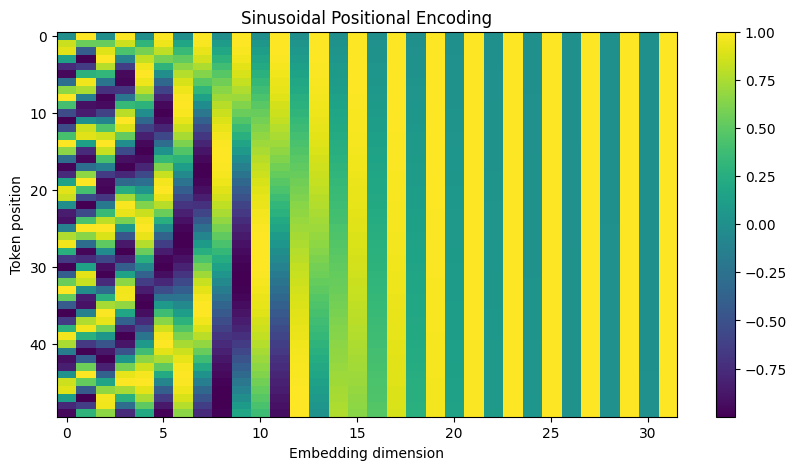

In [83]:

import numpy as np
import matplotlib.pyplot as plt

def positional_encoding(max_len, d_model):
    positions = np.arange(max_len)[:, None]
    dimensions = np.arange(d_model)[None, :]

    angles = positions / np.power(
        10000,
        (2 * (dimensions // 2)) / d_model
    )

    encoding = np.zeros((max_len, d_model))
    encoding[:, 0::2] = np.sin(angles[:, 0::2])
    encoding[:, 1::2] = np.cos(angles[:, 1::2])
    return encoding

pe = positional_encoding(max_len=50, d_model=32)

plt.figure(figsize=(10, 5))
plt.imshow(pe, aspect="auto", cmap="viridis")
plt.xlabel("Embedding dimension")
plt.ylabel("Token position")
plt.title("Sinusoidal Positional Encoding")
plt.colorbar()
plt.show()


Attention mechanism

In [84]:

def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)

    scores = torch.matmul(Q, K.transpose(-2, -1))
    scores = scores / (d_k ** 0.5)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, V)

    return output, weights

Q = torch.randn(1, 3, 4)
K = torch.randn(1, 3, 4)
V = torch.randn(1, 3, 4)

output, weights = scaled_dot_product_attention(Q, K, V)

print("Output shape:", output.shape)
print("Attention weights:", weights)


Output shape: torch.Size([1, 3, 4])
Attention weights: tensor([[[0.4146, 0.3888, 0.1966],
         [0.3500, 0.3202, 0.3298],
         [0.4074, 0.4095, 0.1831]]])


Self-attention

In [85]:

class SelfAttention(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.query = nn.Linear(d_model, d_model)
        self.key = nn.Linear(d_model, d_model)
        self.value = nn.Linear(d_model, d_model)

    def forward(self, x):
        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        return scaled_dot_product_attention(Q, K, V)

x = torch.randn(2, 5, 16)  # batch, sequence length, features

attention = SelfAttention(d_model=16)
context, attention_weights = attention(x)

print("Input:", x.shape)
print("Context:", context.shape)
print("Weights:", attention_weights.shape)


Input: torch.Size([2, 5, 16])
Context: torch.Size([2, 5, 16])
Weights: torch.Size([2, 5, 5])


Masked self-attention

In [86]:

sequence_length = 5

# True means the position is allowed to attend.
causal_mask = torch.tril(
    torch.ones(sequence_length, sequence_length)
).bool()

print(causal_mask.int())

x = torch.randn(1, sequence_length, 8)
Q, K, V = x, x, x

masked_output, masked_weights = scaled_dot_product_attention(
    Q, K, V, mask=causal_mask
)

print("Attention weights:")
print(masked_weights[0].detach())


tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)
Attention weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0224, 0.9776, 0.0000, 0.0000, 0.0000],
        [0.0320, 0.0156, 0.9524, 0.0000, 0.0000],
        [0.0312, 0.0551, 0.0084, 0.9053, 0.0000],
        [0.0603, 0.2121, 0.2466, 0.0813, 0.3998]])


Multi-head attention

In [87]:

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.output_projection = nn.Linear(d_model, d_model)

    def forward(self, x, causal=False):
        batch, seq_len, _ = x.shape

        qkv = self.qkv(x).reshape(
            batch, seq_len, 3, self.num_heads, self.head_dim
        )

        q, k, v = qkv.permute(2, 0, 3, 1, 4)

        mask = None
        if causal:
            mask = torch.tril(
                torch.ones(seq_len, seq_len, device=x.device)
            ).bool()

        context, weights = scaled_dot_product_attention(
            q, k, v, mask
        )

        context = context.transpose(1, 2).contiguous().reshape(
            batch, seq_len, self.d_model
        )

        return self.output_projection(context), weights

mha = MultiHeadSelfAttention(d_model=32, num_heads=4)
x = torch.randn(2, 6, 32)
result, weights = mha(x)

print("Result:", result.shape)
print("Attention weights:", weights.shape)


Result: torch.Size([2, 6, 32])
Attention weights: torch.Size([2, 4, 6, 6])


Cross-attention

In [88]:

class CrossAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, decoder_states, encoder_states):
        output, weights = self.attention(
            query=decoder_states,
            key=encoder_states,
            value=encoder_states
        )
        return output, weights

cross_attention = CrossAttention(d_model=32, num_heads=4)

decoder_states = torch.randn(2, 5, 32)
encoder_states = torch.randn(2, 7, 32)

output, weights = cross_attention(
    decoder_states, encoder_states
)

print("Cross-attention output:", output.shape)
print("Cross-attention weights:", weights.shape)


Cross-attention output: torch.Size([2, 5, 32])
Cross-attention weights: torch.Size([2, 5, 7])


Feed-forward neural network

In [89]:

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        return self.network(x)

ffn = FeedForward(d_model=32, d_ff=128)
x = torch.randn(2, 6, 32)

print("Output shape:", ffn(x).shape)


Output shape: torch.Size([2, 6, 32])


Layer normalization

In [90]:

class TransformerFeedForwardBlock(nn.Module):
    def __init__(self, d_model=32, d_ff=128):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x):
        # Pre-normalization and residual connection
        return x + self.ffn(self.norm(x))

block = TransformerFeedForwardBlock()
x = torch.randn(2, 6, 32)

y = block(x)
print("Input shape:", x.shape)
print("Output shape:", y.shape)


Input shape: torch.Size([2, 6, 32])
Output shape: torch.Size([2, 6, 32])


Build an encoder-decoder Transformer

In [91]:

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len).float().unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-np.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class EncoderLayer(nn.Module):
    def __init__(self, d_model, heads, d_ff):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, heads)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x):
        a, _ = self.attn(self.norm1(x))
        x = x + a
        return x + self.ffn(self.norm2(x))


class DecoderLayer(nn.Module):
    def __init__(self, d_model, heads, d_ff):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.self_attn = MultiHeadSelfAttention(d_model, heads)
        self.norm2 = nn.LayerNorm(d_model)
        self.cross_attn = nn.MultiheadAttention(
            d_model, heads, batch_first=True
        )
        self.norm3 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x, memory):
        a, _ = self.self_attn(self.norm1(x), causal=True)
        x = x + a

        q = self.norm2(x)
        a, _ = self.cross_attn(q, memory, memory)
        x = x + a

        return x + self.ffn(self.norm3(x))


class TinyTransformer(nn.Module):
    def __init__(
        self, vocab_size, d_model=32, heads=4, d_ff=64
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.position = PositionalEncoding(d_model)
        self.encoder = EncoderLayer(d_model, heads, d_ff)
        self.decoder = DecoderLayer(d_model, heads, d_ff)
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, src, tgt):
        src = self.position(self.embedding(src))
        tgt = self.position(self.embedding(tgt))

        memory = self.encoder(src)
        decoded = self.decoder(tgt, memory)

        return self.output(decoded)


model = TinyTransformer(vocab_size=100)

src = torch.randint(0, 100, (2, 6))
tgt = torch.randint(0, 100, (2, 5))

logits = model(src, tgt)

print("Source shape:", src.shape)
print("Target shape:", tgt.shape)
print("Output logits shape:", logits.shape)


Source shape: torch.Size([2, 6])
Target shape: torch.Size([2, 5])
Output logits shape: torch.Size([2, 5, 100])


Build a Transformer in TensorFlow

In [92]:

import tensorflow as tf

class TFEncoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()
        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads
        )
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(d_ff, activation="relu"),
            tf.keras.layers.Dense(d_model)
        ])
        self.norm1 = tf.keras.layers.LayerNormalization()
        self.norm2 = tf.keras.layers.LayerNormalization()

    def call(self, x, training=False):
        a = self.attention(x, x, training=training)
        x = self.norm1(x + a)
        f = self.ffn(x, training=training)
        return self.norm2(x + f)


class TFTransformer(tf.keras.Model):
    def __init__(self, vocab_size, d_model=32, heads=4, d_ff=64):
        super().__init__()
        self.embedding = tf.keras.layers.Embedding(
            vocab_size, d_model
        )
        self.encoder = TFEncoderBlock(d_model, heads, d_ff)
        self.classifier = tf.keras.layers.Dense(vocab_size)

    def call(self, token_ids, training=False):
        x = self.embedding(token_ids)
        x = self.encoder(x, training=training)
        return self.classifier(x)


tf_model = TFTransformer(vocab_size=100)

tokens = tf.random.uniform(
    (2, 6), minval=0, maxval=100, dtype=tf.int32
)

tf_logits = tf_model(tokens)

print("TensorFlow output shape:", tf_logits.shape)
tf_model.summary()


TensorFlow output shape: (2, 6, 100)


Model: "tf_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (2, 6, 32)             │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tf_encoder_block                │ ?                      │         8,544 │
│ (TFEncoderBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (2, 6, 100)            │         3,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,044 (58.77 KB)

 Trainable params: 15,044 (58.77 KB)

 Non-trainable params: 0 (0.00 B)

Train the PyTorch Transformer on a toy next-token task

In [93]:

# Reuse TinyTransformer and the classes defined in Step 11.
# A causal decoder predicts each next token from earlier tokens.
# Here we use a small decoder-only model for next-token training.

class TinyLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model=32, heads=4, d_ff=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.position = PositionalEncoding(d_model)
        self.blocks = nn.ModuleList([
            DecoderOnlyBlock(d_model, heads, d_ff)
            for _ in range(2)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, token_ids):
        x = self.position(self.embedding(token_ids))
        for block in self.blocks:
            x = block(x)
        return self.output(self.norm(x))


class DecoderOnlyBlock(nn.Module):
    def __init__(self, d_model, heads, d_ff):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, heads)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x):
        a, _ = self.attn(self.norm1(x), causal=True)
        x = x + a
        return x + self.ffn(self.norm2(x))


# Create repeating toy sequences: 1,2,3,4,1,2,3,4...
vocab_size = 6
sequence = [1, 2, 3, 4] * 250

inputs, targets = [], []
for i in range(len(sequence) - 6):
    chunk = sequence[i:i + 6]
    inputs.append(chunk[:-1])
    targets.append(chunk[1:])

X = torch.tensor(inputs, dtype=torch.long)
Y = torch.tensor(targets, dtype=torch.long)

model = TinyLanguageModel(vocab_size=vocab_size)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
criterion = nn.CrossEntropyLoss()

for epoch in range(15):
    model.train()
    optimizer.zero_grad()

    logits = model(X)
    loss = criterion(
        logits.reshape(-1, vocab_size),
        Y.reshape(-1)
    )

    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch+1:02d} | Loss: {loss.item():.4f}")


Epoch 01 | Loss: 1.6343
Epoch 02 | Loss: 1.3269
Epoch 03 | Loss: 1.0748
Epoch 04 | Loss: 0.8710
Epoch 05 | Loss: 0.7042
Epoch 06 | Loss: 0.5644
Epoch 07 | Loss: 0.4472
Epoch 08 | Loss: 0.3529
Epoch 09 | Loss: 0.2810
Epoch 10 | Loss: 0.2289
Epoch 11 | Loss: 0.1918
Epoch 12 | Loss: 0.1651
Epoch 13 | Loss: 0.1451
Epoch 14 | Loss: 0.1296
Epoch 15 | Loss: 0.1171
